In [14]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-

#  Copyright (c) 2021 - 2022.  FlexibleLecture@Linkedin
#  All rights reserved.

# Created By  : FlexibleLecture@Linkedin
# Created Date: 1/22/2022
# version ='1.0'

# Demo: Using Barrier Method to Solve a Family of Standard Form LPs

A family of standard form LPs was discussed in book-convex-2004 to explore the total number of Newton steps required as a function of the problem dimension, i.e., $m$:
\begin{equation}
\begin{array}{rccl}
\text{minimize} & c^Tx & \\
\text{subject to} & Ax=b & \text{,} & x \succeq 0 \\
\end{array}
\end{equation}
where $A\in R^{m\times n}$, $n=2m$, and $rank(A)=m$. 

The method to generate the parameters $(A, b, c)$ and initial starting point $x_0$ had also been provided in \cite{book-convex-2004} and it is repeated here.


### Method to generate parameters $(A, b, c)$ and initial starting point $x_0$

1. Let $A=[a_{i,j}]$, where $a_{i,j}\in \mathbf{N}(0, 1)$, i.e., normal distribution with zero mean and unit one variance
1. Let $x^*=[x^*_{j}]$, where $x^*_{j}\in \mathbf{U}(0, 1)$, i.e., uniform distribution between 0 and 1
1. Let $b\leftarrow Ax^*$
1. Let $\nu=[\nu_i]$, where $\nu_i \in \mathbf{N}(0, 1)$
1. Let $\lambda=[\lambda_j]$, where $\lambda_j \in \mathbf{U}(0, 1)$
1. Let $c=A^T\nu+\lambda$
1. Run the centering step once with $t=1$ and initial point $x^*$ to get a starting point $x_0$ at the central path with $t=1$ and a duality gap = $m$.


In this way, 
$$c^Tx^*=\lambda^Tx^*+\nu^T(Ax^*)=\lambda^Tx^*+\nu^Tb$$
where $x^*\in \{x|Ax=b,x\succeq 0\}$. The optimality conditions are satisfied, so $x^*$ is an optimal solution.

Since $\lambda \succeq 0$ and $x^*\succeq 0$, $c^Tx^*$ is lower bounded by $\nu^Tb$.

However, the above method does not consider whether the LP solution is unique, and whether the numerical implementation of the barrier method is robust. The robustness and the uniqueness of the optimal solution will provide more convenience to verify the implementation of the barrier method in Python.

If $x^*$ is a unique attainable optimal point of the LP problem in Equ 1, let it be expressed as (ignoring the ordering the zeros)
$$
x^* = \left[\begin{array}{c}
\vec{0}_{l} \\
\vec{\theta}_{n-l} \\
\end{array} \right]
$$
where $\vec{\theta}_{n-l} \succ 0$, $0\leq l \leq n$. Let $A=[A_{1,l}; A_{2,n-l}]$ then $Ax^*=b$ becomes $A_{2,n-l}\vec{\theta}_{n-l}=b$. If $n-l>m$, then a small ball in the null space of $A_{2,n-l}$ with a dimension of $n-l-m$ around $\vec{\theta}_{n-l}$ is also feasible for $Ax=b$. Unless $c$ is orthogonal to this ball, $x^*$ won't be the optimal solution. If $c$ is orthogonal to this ball, then any point within this ball is also optimal, which is in contradict to the assumption that $x^*$ is unique.

So, to attain a unique optimal point, it is  requiring that
$$
\begin{array}{rcl}
n - l \leq m & \text{i.e. } & l \geq n-m 
\end{array}
$$

In this demo, a revised algorithm is used to construct the LPs parameters, $A, b, c$ in the such a way that the feasible set $\{x|Ax=b,x\succeq 0\}$ is bounded, and the LP in Equ. 1 is lowed bounded. The reason for bounding will be explained in the following:

In algorithm $c$ is selected to be $$ c=A^T\nu+\lambda$$
thus 
$$
c^Tx=\lambda^Tx+\nu^Tb
$$
which is lowed bounded by $\nu^Tb$. However, due to the numerical quantization error, $c$ may be biased by a random error $\sigma$, i.e., 
 $$c=\lambda^T +A^T\nu+\sigma$$ 
then,
$$
c^Tx=\lambda^Tx+\mu^Tb+\sigma x
$$
where $\sigma$ is a small random error vector in any possible direction. If $x\in\{x|Ax=b,x\succeq 0\}$ is unbounded, then $\sigma x$ may also be unbounded with some probability, leading to the failure in the convergence of the LP problem (Note that the probability of convergence failure depends on the directions of the $\sigma$ and $x$). To prevent this risk, $A$ is constructed in a way that $\{x|Ax=b,x\succeq 0\}$ is bounded. 


### A revised Method to generate parameters $(A, b, c)$ and initial starting point $x_0$, with a unique optimal point, and bounded feasible set $\{x|Ax=b,x\succeq 0, rank(A)=m\}$

1. INPUT: $n-m\leq l \leq m$ and $l$ (because, for a unique optimal point, it requires that $n-m \leq l \leq n$; for a bounded feasible set $\{x|Ax=b,x\succeq 0, rank(A)=m\}$, it requires $l\leq m$ (which will be seen in a following step))
1. Generate $x^*=\left[\begin{array}{c}
\vec{0}_l \\
\vec{\theta}_{n-l}
\end{array} \right]$, where $\vec{\theta}_{n-l}\in \mathbf{U}[0,1]^{n-l}$
1. Generate $\lambda=\left[\begin{array}{c}
\vec{\zeta}_{l} \\
\vec{0}_{n-l} \\
\end{array} \right]$, where $\zeta_{l}\in \mathbf{U}[0,1]^l$

For {$i$ from $1$ to $n-l$}
Let $d_i \leftarrow \left[\begin{array}{l}
	\vec{\xi}_{l,i} (\in \mathbf{U}(0,1)^l) \\
	\vec{0}_{i-1} \\
	-0.5 * x^*[l+i] \\
	\vec{0}_{n-l-i} \\ 
	\end{array}\right]$
Let $x_{e,i}\leftarrow x^* + d_i$

EndFor

In this way, $\{d_i\},i=1,...,n-l$ are linear independent; and $\{x|x^*+\displaystyle{\sum_{i=1}^{n-l}}w_id_i \succeq 0\}$ is bounded (at least by $-\dfrac{2(n-l)}{min(\xi_{l,i})} \leq w_i \leq 2$)
1. Let $B=[d_1, d_2, ..., d_{n-l}]$, and calculate $N_B$ satisfying $N_B\times B=\vec{0}_{l\times (n-l)}$, i.e., $\mathcal{R}(B)\perp \mathcal{R}(N_B^T)$, or $\mathcal{R}(B)=\mathcal{N}(N_B)$
1. Select $l$ row vectors from $N_B$ plus any other $m-l$ (which requires that $m\geq l$) linearly independent row vectors (denoted as $D$) to create $A=\left[\begin{array}{c}
N_B \\
D \\
\end{array}\right]$ with a rank of $m$. 
In this way, $Ad_i=0, i=1,2,...,n-l$, and the null space of $A$, $\mathcal{N}(A)$ will satisfy: 
$$
\mathcal{N}(A) \subseteq \mathcal{N}(N_B)=\mathcal{R}(B)=\{x|x=\displaystyle{\sum_{i=1}^{n-l}}w_id_i\}
$$
($\mathcal{N}(A) \subseteq \mathcal{N}(N_B)$ is because, any $y$ satisfying $Ay=0$ must also satisfy $N_By=0$)
In case $l=m, n=2m$ as an example, $A=N_B$, and $rank(A)=m$. 
1. Let $b\leftarrow Ax^*$
In this way, $\{x|Ax=b,x\succeq 0 \} = \{x^*+y|Ay=0, x^*+y\succeq 0\} \subseteq \{x|x^*+\displaystyle{\sum_{i=1}^{n-l}}w_id_i \succeq 0\}$ is also bounded.
1. Let $x_0=\dfrac{1}{n-l}\displaystyle{\sum_{i=1}^{n-l}}(x_{e,i})$
In this way, $x_0\succeq 0$ and $Ax_0=\dfrac{1}{n-l}\displaystyle{\sum_{i=1}^{n-l}}Ax_{e_i}=\dfrac{1}{n-l}\displaystyle{\sum_{i=1}^{n-l}}(Ax^*+Ad_i)=b$ (due to the fact that $Ax^*=d, Ad_i=0)$
1. Let $\nu\leftarrow\mathbf{N}(0, 1)^m$
1. Let $c\leftarrow \lambda-A^T\nu$



In the demo, let $n=2m$, $l=n-m=m$. 

In the experiment, to allow completion of three outer iteration when $n$ is as large as 500, the threshold for ill-conditional KKT matrix is 
$$
\kappa(H_{KKT}) \geq 10^{30}	
$$
Note the in the numerical experiment, the KKT matrix in the Newton method is
$$
H_{KKT}=\left[\begin{array}{cc}
diag[\dfrac{1}{x^2}] & A^T \\
A & 0 \\
\end{array} \right]
$$
If let $B=(-A)diag[x^2]$, Then,
$$
\left[\begin{array}{cc}
I_n & 0 \\
B & I_m \\
\end{array}\right] H_{KKT} \left[\begin{array}{cc}
I_n & B^T \\
0 & I_m \\
\end{array} \right] = \left[\begin{array}{cc}
diag[\dfrac{1}{x^2}] & 0 \\
0 & -Adiag[x^2]A^T \\
\end{array} \right]
$$
The conditional number of the $H_{KKT}$ is
$$
\kappa(H_{KKT}) \approx \dfrac{max_j\{1/x^2_j\}}{min_j\{a_j^Tx_j^2a_j\}}
$$
When $x$ is approaching $x^*$, some elements, $x_j$, are approaching zero (if $l>0$), the above conditional number is large, bringing ill-conditioned KKT matrix. 

Further note that $x_{nt}$ is calculated from the KKT system
$$\begin{array}{rcl}
(\nabla^2f)x_{nt}+A^Tw = -\nabla f & & Ax_{nt}=0 \\
\end{array}
$$
or,
$$
x_{nt}^T(\nabla^2f)x_{nt}+(Ax_{nt})^Tw = -x_{nt}^T\nabla f
$$
In theory, $Ax_{nt}=0$, however, due to numerical quantization error, $(Ax_{nt})^Tw$ is no longer zero, and may be negative, resulting in $x_{nt}^T(\nabla^2f)x_{nt}\neq  -x_{nt}^T\nabla f$, or even worst, $x_{nt}^T\nabla>0$, i.e, $x_{nt}$ is not a negative gradient direction, but a positive one! In this case, in the backtracking line search,
$$
t = min_{k}\{t=\beta^k|f(x+t x_{nt}) \leq f(x)+\alpha t x_{nt}\nabla f\} 
$$
 the resulting step $t$ is very close to 0 for some Newton iterations; i.e., the resulting $x$ is stumbled around with tiny steps until a positive gradient is found again.

In [15]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator
from scipy.linalg import null_space

 $f_0(x)=c^Tx$
 
 $\nabla f_0(x)=c$
 
 $\nabla^2 f_0(x)=0$

In [16]:
def my_f_0(x, t, A, b, c):
    """
    $f_0(x)=c^Tx$
    :param x:
    :param t:
    :param A:
    :param b:
    :param c:
    :return:
    """
    return (c.T @ x).item()


def my_f_0_feasible(x, t, A, b, c):
    return True


def my_gradient_f_0(x, t, A, b, c):
    """
    $\nabla f_0(x)=c$
    :param x:
    :param t:
    :param A:
    :param b:
    :param c:
    :return:
    """
    return c


def my_hessian_f_0(x, t, A, b, c):
    """
    $\nabla^2 f_0(x)=0$
    :param x:
    :param t:
    :param A:
    :param b:
    :param c:
    :return:
    """
    return np.zeros((len(x), len(x)))

$\phi(x)=-1\sum \log x_i$

$\nabla \phi(x)=\dfrac{-1}{x}$

$\nabla^2 \phi(x)=\dfrac{1}{x^2}$

In [17]:
def my_phi(x, t, A, b, c):
    """
    $\phi(x)=-1\sum \log x_i$
    :param x:
    :param t:
    :param A:
    :param b:
    :param c:
    :return:
    """
    return -1 * np.sum(np.log(x))


def my_phi_feasible(x, t, A, b, c):
    return np.all(x > 0)


def my_gradient_phi(x, t, A, b, c):
    """
    $\nabla \phi(x)=\dfrac{-1}{x}$
    :param x:
    :param t:
    :param A:
    :param b:
    :param c:
    :return:
    """
    return -1 / x


def my_hessian_phi(x, t, A, b, c):
    """
    $\nabla^2 \phi(x)=\dfrac{1}{x^2}$
    :param x:
    :param t:
    :param A:
    :param b:
    :param c:
    :return:
    """
    return np.diag(np.squeeze(1 / (x ** 2)))

$f(x)=tf_0(x)+\phi(x)$

$\nabla f(x)=t\nabla f_0(x)+\nabla \phi(x)$

$\nabla^2 f(x)=t\nabla^2 f_0(x)+\nabla^2 \phi(x)$

In [18]:
def my_f(x, t, A, b, c):
    """
    $f(x)=tf_0(x)+\phi(x)$
    :param x:
    :param t:
    :param A:
    :param b:
    :param c:
    :return:
    """
    return t * my_f_0(x, t, A, b, c) + my_phi(x, t, A, b, c)


def my_f_feasible(x, t, A, b, c):
    return my_f_0_feasible(x, t, A, b, c) and my_phi_feasible(x, t, A, b, c)


def my_gradient_f(x, t, A, b, c):
    """
    $\nabla f(x)=t\nabla f_0(x)+\nabla \phi(x)$
    :param x:
    :param t:
    :param A:
    :param b:
    :param c:
    :return:
    """
    return t * my_gradient_f_0(x, t, A, b, c) + my_gradient_phi(x, t, A, b, c)


def my_hessian_f(x, t, A, b, c):
    """
    $\nabla^2 f(x)=t\nabla^2 f_0(x)+\nabla^2 \phi(x)$
    :param x:
    :param t:
    :param A:
    :param b:
    :param c:
    :return:
    """
    return t * my_hessian_f_0(x, t, A, b, c) + my_hessian_phi(x, t, A, b, c)

Calculation of the Newton step: $\Delta x_{nt}=-\nabla^2f(x)^{-1}\nabla f(x)$

In [19]:
def my_newton_step_decrement(x, args):
    """
    Calculation of the Newton step: $\Delta x_{nt}=-\nabla^2f(x)^{-1}\nabla f(x)$
    :param args:
    :return:
    """
    (t, A, b, c) = args
    (m, n) = A.shape
    gradient = my_gradient_f(x, *args)
    hessian = my_hessian_f(x, *args)
    KKT = np.block([[hessian, A.T], [A, np.zeros((m, m))]])
    residual = np.block([[gradient], [np.zeros((m, 1))]])
    cond = np.linalg.cond(KKT)
    # relax the condition number to be as large as 1e30 in this family of LP problems
    # refer to the FlexibleLecture note
    if cond < 1e30:
        x_nt_w = np.linalg.inv(KKT) @ (-1 * residual)
        x_nt = x_nt_w[0: n]
        # w = x_nt_w[n:]
        decrement = x_nt.T @ hessian @ x_nt
        return x_nt, decrement.item()
    else:
        raise RuntimeError('the KKT system is not invisible')

Backtracking line search implementation, see to Algorithm 9.2 in the textbook

In [20]:
def backtracking_line_search(f, df, x, delta_x, alpha, beta, args):
    """
    Backtracking line search implementation, see to Algorithm 9.2 in the textbook
    :param f:
    :param df:
    :param x:
    :param delta_x:
    :param alpha:
    :param beta:
    :param args:
    :return:
    """
    s = 1
    while (not my_f_feasible(x + delta_x * s, *args)) \
            or f(x + delta_x * s, *args) > f(x, *args) + alpha * s * ((df(x, *args).T @ delta_x).item()):
        s = beta * s
    return s

The centering step, to compute $x^*(t)$ by minimizing $tf_0+\phi$, starting from x0, with the parameters,
$\alpha$, $\beta$ in the backtracking line search method.

In [21]:
def centering_step(x0, epsilon, alpha, beta, barrier_t, A, b, c, max_newton_iteration=100):
    """
    The centering step, to compute $x^*(t)$ by minimizing $tf_0+\phi$, starting from x0, with the parameters,
    $\alpha$, $\beta$ in the backtracking line search method.
    :param x0:
    :param epsilon:
    :param alpha:
    :param beta:
    :param barrier_t:
    :param A:
    :param b:
    :param c:
    :return:
    """
    x = x0
    args = (barrier_t, A, b, c)
    x_nt, decrement = my_newton_step_decrement(x, args)

    tx = []
    fx = [my_f(x, *args)]
    decrements = [decrement]

    iteration = 1  # a Newton iteration has been executed
    while decrement / 2 > epsilon:
        t = backtracking_line_search(my_f, my_gradient_f, x, x_nt, alpha, beta, args)
        #print(r'Info: iteration={}, decrement={}, t={}'.format(iteration, decrement, t))

        x_next = x + t * x_nt
        x = x_next
        x_nt, decrement = my_newton_step_decrement(x, args)

        tx.append(t)
        fx.append(my_f(x, *args))
        decrements.append(decrement)

        iteration = iteration + 1
        
        if iteration > max_newton_iteration:
            print('Error: Newton method not converged!')
            break

    #print(r'Info: iteration={}, decrement={}'.format(iteration, decrement))
    n_iter = iteration
    xt = x
    return xt, n_iter, fx, decrements, tx

A revised Method to generate parameters $(A, b, c)$ and initial starting point $x_0$,
with a unique optimal point, and bounded feasible set $\{x|Ax=b,x\succeq 0, rank(A)=m\}$

In [22]:
def get_A_b_c(m, n, l):
    """
    A revised Method to generate parameters $(A, b, c)$ and initial starting point $x_0$,
    with a unique optimal point, and bounded feasible set $\{x|Ax=b,x\succeq 0, rank(A)=m\}$
    :param m:
    :param n:
    :param l:
    :return:
    """
    if n != 2*m:
        raise RuntimeError('currently only support n = 2m scenarios')

    x_asterisk = np.random.uniform(low=0, high=1, size=(n, 1))
    x_asterisk[0:l] = 0
    lambda_ = np.random.uniform(low=0, high=1, size=(n, 1))
    lambda_[l:] = 0

    B = np.zeros((n, n-l))
    E = np.zeros((n, n-l))
    for li in range(n-l):
        xe = x_asterisk.copy()
        xe[0:l] = np.random.uniform(low=0, high=1, size=(l, 1))
        xe[l+li] = 0.5 * x_asterisk[l+li]  # $x_{e,i}$
        dx = xe - x_asterisk  # $d_i=x_{e,i}-x^*$
        B[:, li] = np.squeeze(dx)
        E[:, li] = np.squeeze(xe)

    x0 = np.reshape(np.average(E, axis=1), (-1, 1))  # $x_0=\dfrac{1}{n-l}\displaystyle{\sum_{i=1}^{n-l}}(x_{e,i})$
    
    Ns_B = null_space(B.T)
    A = Ns_B[:, 0:m].T  # only the first m is selected if n=2m

    b1 = A @ x0
    b2 = A @ x_asterisk
    if not np.allclose(b1, b2):
        raise RuntimeError('x0, xp should both satisfy Ax = b')
    b = b1

    nu = np.random.normal(loc=0, scale=1, size=(m, 1))
    c = lambda_ - A.T @ nu

    return A, b, c, x_asterisk, x0, nu

plot the convergence of the barrier method versus m in ms

In [23]:
def plot_barrier_method_convergence(seed, mu, ms):
    """
    plot the convergence of the barrier method versus m in ms
    :param seed:
    :param mu:
    :return:
    """
    plt.figure(figsize=(12, 9))
    ax1 = plt.subplot(3, 1, 1)
    ax1_twin = ax1.twinx()

    ax2 = plt.subplot(3, 1, 2)
    ax2_twin = ax2.twinx()

    ax3 = plt.subplot(3, 1, 3)
    ax3_twin = ax3.twinx()

    m_s = ms
    colors = ['black', 'purple', 'orange', 'magenta']
    markers = ['o', 's', 'v', '<']
    for m_i, m in enumerate(m_s):
        #print('Info: m={}'.format(m))
        color = colors[m_i]
        marker = markers[m_i]
        n = 2 * m
        np.random.seed(seed)
        if m > n:
            raise RuntimeError('it requires m > n')

        l = n-m
        A, b, c, x_asterisk, x0, nu = get_A_b_c(m, n, l)

        alpha = 0.01
        beta = 0.5
        epsilon = 1e-5
        duality_gap_epsilon = n * 1e-6

        f0_asterisk = c.T @ x_asterisk
        #print('Info: optimal f0 = {}'.format(f0_asterisk))

        t0 = 1
        t = t0

        # run centering step once to ensure that the initial point is on the central path with t_0 = 1
        args = (t, A, b, c)
        xt, n_iter, fx, decrement, tx = centering_step(x0, epsilon, alpha, beta, *args)
        x0 = xt
        t = mu * t

        accumulate_iteration = 0

        dual_gaps = []
        decrements = []
        iteration_index_vs_decrement = []
        tx_list = []
        f0_x = []
        while True:
            args = (t, A, b, c)

            xt, n_iter, fx, decrement, tx = centering_step(x0, epsilon, alpha, beta, *args)

            # save the intermediate statistics
            f0_x = f0_x + [my_f_0(x0, *args)] * n_iter
            tx_list = tx_list + tx
            dual_gaps = dual_gaps + [m / (t / mu)] * n_iter  # saving dual gap before centering step
            decrements = decrements + decrement
            iteration_index_vs_decrement = iteration_index_vs_decrement + [i for i in range(accumulate_iteration, accumulate_iteration + n_iter)]
            accumulate_iteration = accumulate_iteration + n_iter-1

            x0 = xt
            if m / t < duality_gap_epsilon:
                break
            else:
                t = mu * t

        f0_x = f0_x + [my_f_0(x0, *args)]
        dual_gaps = dual_gaps + [m / t]

        ax1.semilogy(iteration_index_vs_decrement + [max(iteration_index_vs_decrement)], dual_gaps, color=color, linestyle='solid', label='m={}'.format(m))
        ax1_twin.semilogy(iteration_index_vs_decrement, decrements, marker='+', color=color, linestyle='dotted')
        ax1.xaxis.set_minor_locator(MultipleLocator(1))
        ax1.xaxis.grid(True, which='both')
        ax1.set_xlabel('iteration')
        ax1.set_ylabel('duality_gap')
        ax1_twin.set_ylabel(r'$\lambda^2$')

        ax2.plot(range(1, len(tx_list) + 1), tx_list, marker=marker, fillstyle='none', color=color, linestyle='solid', label='m={}'.format(m))
        ax2_twin.semilogy(iteration_index_vs_decrement, decrements, marker='+', color=color, linestyle='dotted')
        ax2.xaxis.set_minor_locator(MultipleLocator(1))
        ax2.xaxis.grid(True, which='both')
        ax2.set_xlabel('iteration')
        ax2.set_ylabel('newton step length: t')
        ax2_twin.set_ylabel(r'$\lambda^2$')

        ax3.semilogy(iteration_index_vs_decrement + [max(iteration_index_vs_decrement)], np.squeeze(np.abs(np.array(f0_x)-f0_asterisk)), color=color, linestyle='dashed', label='m={},fp={:.3f}'.format(m, f0_asterisk.item()))
        ax3_twin.semilogy(iteration_index_vs_decrement, decrements, marker='+', color=color, linestyle='dotted')
        ax3.xaxis.set_minor_locator(MultipleLocator(1))
        ax3.xaxis.grid(True, which='both')
        ax3.set_xlabel('iteration')
        ax3.set_ylabel(r'f0-f^*')
        ax3_twin.set_ylabel(r'$\lambda^2$')

    ax1.legend()
    ax2.legend()
    ax3.legend()
    plt.show()

plot the figure about the accumulate iterations versus m, each with n_dial simulation

In [24]:
def plot_accumulate_iteration_vs_m(n_dial, mu, ms):
    """
    plot the figure about the accumulate iterations versus m, each with n_dial simulation
    :param n_dial:
    :param mu:
    :param ms:
    :return:
    """
    n_seed = n_dial
    m_s = ms
    num_total_iterations = np.zeros((n_seed, len(m_s)))
    for seed in range(n_seed):
        np.random.seed(seed)

        for m_i, m in enumerate(m_s):

            n = 2 * m
            if m > n:
                raise RuntimeError('it requires m > n')

            l = n-m
            A, b, c, x_asterisk, x0, nu = get_A_b_c(m, n, l)

            alpha = 0.01
            beta = 0.5
            epsilon = 1e-5
            duality_gap_epsilon = n * 1e-6

            f0_asterisk = c.T @ x_asterisk
            #print('[{},{}] optimal f0 = {}'.format(seed, m, f0_asterisk))

            t0 = 1
            t = t0

            # To ensure that the initial point is on the central path with t_0 = 1
            args = (t, A, b, c)
            xt, n_iter, fx, decrement, tx = centering_step(x0, epsilon, alpha, beta, *args)
            x0 = xt
            t = mu * t

            accumulate_iteration = 0

            while True:
                args = (t, A, b, c)

                xt, n_iter, fx, decrement, tx = centering_step(x0, epsilon, alpha, beta, *args)
                x0 = xt
                accumulate_iteration = accumulate_iteration + n_iter

                if m / t < duality_gap_epsilon:
                    break
                else:
                    t = mu * t

            num_total_iterations[seed][m_i] = accumulate_iteration

    #fid = open('{}.pickle'.format(np.random.random_sample()), 'wb')
    #pickle.dump(num_total_iterations, fid)
    #fid.close()

    avg_num_iter = np.average(num_total_iterations, axis=0)
    std_num_iter = np.std(num_total_iterations, axis=0)
    plt.figure(figsize=(12, 4))
    x = m_s
    y = avg_num_iter
    yerr = std_num_iter

    plt.errorbar(x, y, yerr=yerr, label=r'mean$\pm\sigma$')
    plt.xlabel('m')
    plt.ylabel('num. Newton steps')
    plt.legend()
    plt.grid()
    plt.show()

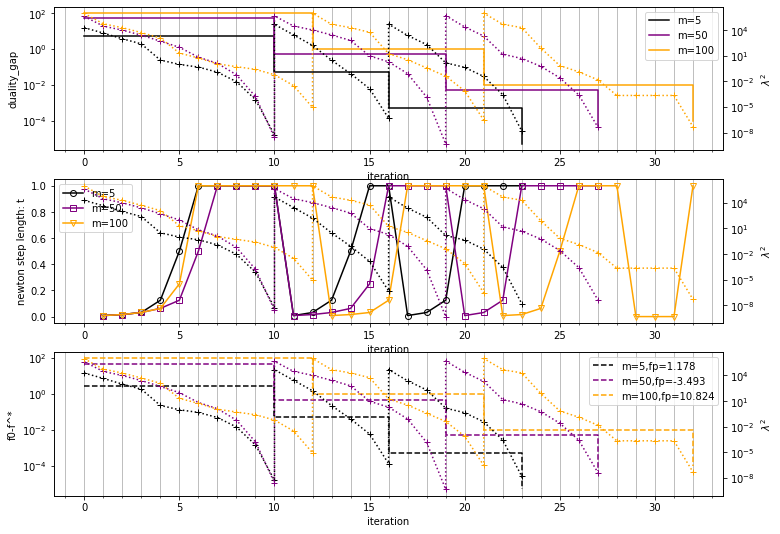

In [25]:
if __name__ == "__main__":
    seed = 1
    ms = [5, 50, 100]
    plot_barrier_method_convergence(seed, mu=100, ms=ms)

Error: Newton method not converged!
Error: Newton method not converged!


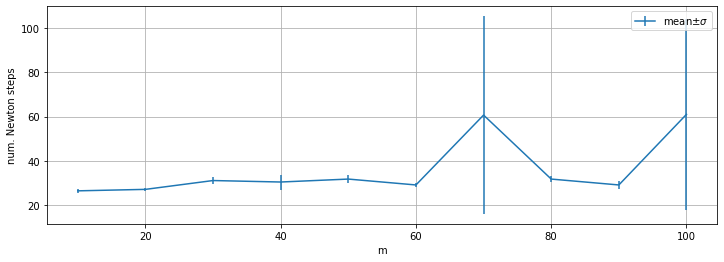

In [26]:
if __name__ == "__main__":
    ms = [10 * i for i in range(1, 11)]
    plot_accumulate_iteration_vs_m(n_dial=3, mu=100, ms=ms)